In [1]:
from pathlib import Path
import pandas as pd

carpeta_datos = Path("Datos/procesados")
carpeta_analisis = Path("Datos/analisis")
carpeta_analisis.mkdir(parents=True, exist_ok=True)

archivo = carpeta_datos / "reservas_individuales_amplias.csv"

reservas = pd.read_csv(
    archivo,
    encoding="utf-8-sig",
    parse_dates=["fecha"]
)

reservas["anio"] = reservas["fecha"].dt.year.astype("Int64")
reservas["mes"] = reservas["fecha"].dt.to_period("M").astype("string")

print("Registros:", len(reservas))
print("Centros:", reservas["Centro deportivo"].nunique())

print("\nReservas por año:")
print(reservas.groupby("anio").size())

print("\nPrimera fecha:", reservas["fecha"].min())
print("Última fecha:", reservas["fecha"].max())

Registros: 417661
Centros: 48

Reservas por año:
anio
2025    256122
2026    161539
dtype: int64

Primera fecha: 2025-01-02 00:00:00
Última fecha: 2026-08-31 00:00:00


In [2]:
cobertura_mensual = (
    reservas.groupby(
        ["Centro deportivo", "mes"],
        as_index=False
    )
    .agg(
        reservas=("fecha", "size"),
        dias_con_registros=("fecha", "nunique"),
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max")
    )
    .sort_values(["Centro deportivo", "mes"])
)

display(cobertura_mensual.head(20))

,Centro deportivo,mes,reservas,dias_con_registros,primera_fecha,ultima_fecha
0,Daoíz y Velarde,2025-11,216,30,2025-11-01,2025-11-30
1,Daoíz y Velarde,2025-12,215,28,2025-12-01,2025-12-30
2,Daoíz y Velarde,2026-01,263,30,2026-01-02,2026-01-31
3,Daoíz y Velarde,2026-02,256,28,2026-02-01,2026-02-28
4,Daoíz y Velarde,2026-03,323,31,2026-03-01,2026-03-31
5,Daoíz y Velarde,2026-04,340,30,2026-04-01,2026-04-30
6,Daoíz y Velarde,2026-05,259,30,2026-05-02,2026-05-31
7,Daoíz y Velarde,2026-06,196,30,2026-06-01,2026-06-30
8,Daoíz y Velarde,2026-07,157,31,2026-07-01,2026-07-31
9,Entrevias,2025-11,223,27,2025-11-01,2025-11-30


In [3]:
# Todos los meses comprendidos entre las fechas del conjunto.
meses = pd.period_range(
    start=reservas["fecha"].min(),
    end=reservas["fecha"].max(),
    freq="M"
).astype(str)

tabla_meses = cobertura_mensual.pivot(
    index="Centro deportivo",
    columns="mes",
    values="reservas"
).reindex(columns=meses)

display(tabla_meses)

# Centros que tienen al menos un mes sin registros individuales.
centros_a_revisar = tabla_meses.loc[
    tabla_meses.isna().any(axis=1)
]

print("Centros con algún mes sin registros:", len(centros_a_revisar))
display(centros_a_revisar)

,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
Centro deportivo,,,,,,,,,,,,,,,,,,,,
Daoíz y Velarde,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,216.0,215.0,263.0,256.0,323.0,340.0,259.0,196.0,157.0,NaN
Entrevias,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,223.0,190.0,168.0,176.0,285.0,306.0,283.0,254.0,168.0,268.0
Adelfas,142.0,183.0,97.0,156.0,185.0,175.0,70.0,NaN,NaN,NaN,19.0,119.0,116.0,122.0,125.0,215.0,186.0,153.0,123.0,NaN
Alfredo Goyeneche,347.0,517.0,233.0,359.0,448.0,409.0,328.0,NaN,531.0,504.0,363.0,257.0,255.0,303.0,460.0,419.0,403.0,458.0,NaN,NaN
Aluche,271.0,331.0,196.0,272.0,279.0,229.0,205.0,162.0,408.0,399.0,292.0,205.0,213.0,194.0,361.0,382.0,306.0,271.0,137.0,252.0
Barajas,378.0,452.0,546.0,525.0,673.0,603.0,524.0,519.0,727.0,750.0,692.0,584.0,617.0,652.0,749.0,749.0,771.0,628.0,538.0,548.0
Blanca Fernández Ochoa,548.0,612.0,779.0,761.0,736.0,676.0,655.0,628.0,765.0,730.0,791.0,660.0,803.0,768.0,772.0,812.0,843.0,722.0,552.0,797.0
CDM El Quijote,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,494.0,322.0,370.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Centro Integrado Arganzuela,623.0,742.0,394.0,519.0,686.0,564.0,449.0,NaN,791.0,840.0,664.0,448.0,424.0,546.0,863.0,850.0,726.0,579.0,364.0,NaN


Centros con algún mes sin registros: 27


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
Centro deportivo,,,,,,,,,,,,,,,,,,,,
Daoíz y Velarde,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,216.0,215.0,263.0,256.0,323.0,340.0,259.0,196.0,157.0,NaN
Entrevias,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,223.0,190.0,168.0,176.0,285.0,306.0,283.0,254.0,168.0,268.0
Adelfas,142.0,183.0,97.0,156.0,185.0,175.0,70.0,NaN,NaN,NaN,19.0,119.0,116.0,122.0,125.0,215.0,186.0,153.0,123.0,NaN
Alfredo Goyeneche,347.0,517.0,233.0,359.0,448.0,409.0,328.0,NaN,531.0,504.0,363.0,257.0,255.0,303.0,460.0,419.0,403.0,458.0,NaN,NaN
CDM El Quijote,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,494.0,322.0,370.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Centro Integrado Arganzuela,623.0,742.0,394.0,519.0,686.0,564.0,449.0,NaN,791.0,840.0,664.0,448.0,424.0,546.0,863.0,850.0,726.0,579.0,364.0,NaN
Daoíz y Velarde,293.0,304.0,205.0,279.0,303.0,232.0,210.0,NaN,252.0,267.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
El Quijote,327.0,575.0,273.0,465.0,664.0,613.0,628.0,568.0,757.0,551.0,NaN,NaN,NaN,408.0,643.0,648.0,797.0,631.0,510.0,554.0
Entrevias,214.0,315.0,118.0,232.0,261.0,236.0,243.0,312.0,293.0,306.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
cobertura_mensual.to_csv(
    carpeta_analisis / "cobertura_mensual.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_meses.to_csv(
    carpeta_analisis / "reservas_por_centro_y_mes.csv",
    encoding="utf-8-sig"
)

caso_samaranch = cobertura_mensual.loc[
    cobertura_mensual["Centro deportivo"]
    .str.contains("Samaranch", case=False, na=False)
]

display(caso_samaranch)

,Centro deportivo,mes,reservas,dias_con_registros,primera_fecha,ultima_fecha
562,Marqués de Samaranch,2025-01,1079,27,2025-01-02,2025-01-31
563,Marqués de Samaranch,2025-02,1056,28,2025-02-01,2025-02-28
564,Marqués de Samaranch,2025-03,1553,31,2025-03-01,2025-03-31
565,Marqués de Samaranch,2025-04,1101,26,2025-04-01,2025-04-30
566,Marqués de Samaranch,2025-05,1159,28,2025-05-03,2025-05-31
567,Marqués de Samaranch,2025-06,1198,30,2025-06-01,2025-06-30
568,Marqués de Samaranch,2025-07,998,29,2025-07-01,2025-07-30
569,Marqués de Samaranch,2025-09,1088,30,2025-09-01,2025-09-30
570,Marqués de Samaranch,2025-10,1265,31,2025-10-01,2025-10-31
571,Marqués de Samaranch,2025-11,1211,28,2025-11-02,2025-11-30


In [5]:
# Cargar todos los tipos de uso de pádel aceptados y validados.
usos_padel = pd.read_csv(
    carpeta_datos / "padel_validos.csv",
    encoding="utf-8-sig",
    parse_dates=["fecha"]
)

# Seleccionar Samaranch.
samaranch = usos_padel.loc[
    usos_padel["Centro deportivo"].str.contains(
        "Samaranch", case=False, na=False
    )
].copy()

samaranch["mes"] = samaranch["fecha"].dt.to_period("M").astype("string")

# Contar registros de cada tipo por mes.
resumen_samaranch = (
    samaranch.groupby(["mes", "Tipo de ocupación"])
    .size()
    .unstack("Tipo de ocupación")
)

# Incluir todos los meses, aunque no tengan registros.
meses_revision = pd.period_range(
    "2025-01", "2026-08", freq="M"
).astype(str)

resumen_samaranch = resumen_samaranch.reindex(meses_revision)

display(resumen_samaranch)

Tipo de ocupación,Reserva Individual,Reserva Interna Individual,Reserva Interna de Temporada,Reserva de Escuela,Reserva de Temporada
2025-01,1079.0,17.0,18.0,364.0,38.0
2025-02,1056.0,NaN,NaN,356.0,36.0
2025-03,1553.0,NaN,NaN,378.0,38.0
2025-04,1101.0,1.0,NaN,340.0,48.0
2025-05,1159.0,2.0,NaN,364.0,32.0
2025-06,1198.0,NaN,NaN,248.0,64.0
2025-07,998.0,6.0,6.0,28.0,159.0
2025-08,NaN,NaN,NaN,NaN,NaN
2025-09,1088.0,6.0,9.0,301.0,1.0
2025-10,1265.0,1.0,4.0,395.0,35.0


In [6]:
# 1. Preparar el mes en las dos tablas.
reservas["mes"] = reservas["fecha"].dt.to_period("M").astype(str)
usos_padel["mes"] = usos_padel["fecha"].dt.to_period("M").astype(str)

# 2. Crear todas las combinaciones de centro y mes.
centros = sorted(reservas["Centro deportivo"].dropna().unique())

meses = pd.period_range(
    reservas["fecha"].min(),
    reservas["fecha"].max(),
    freq="M"
).astype(str)

indice = pd.MultiIndex.from_product(
    [centros, meses],
    names=["Centro deportivo", "mes"]
)

# 3. Contar registros individuales y registros de todos los usos.
individuales = reservas.groupby(
    ["Centro deportivo", "mes"]
).size()

todos_usos = usos_padel.groupby(
    ["Centro deportivo", "mes"]
).size()

# Aquí el cero significa "cero registros encontrados en el archivo".
# No confirma que hubiera cero actividad real.
revision_cobertura = pd.DataFrame(index=indice)

revision_cobertura["registros_individuales"] = (
    individuales.reindex(indice, fill_value=0)
)

revision_cobertura["registros_todos_usos"] = (
    todos_usos.reindex(indice, fill_value=0)
)

revision_cobertura = revision_cobertura.reset_index()

# 4. Clasificar cada combinación.
revision_cobertura["situacion"] = "Con registros individuales"

sin_individuales = revision_cobertura["registros_individuales"].eq(0)
sin_ningun_uso = revision_cobertura["registros_todos_usos"].eq(0)

revision_cobertura.loc[
    sin_individuales & ~sin_ningun_uso, "situacion"
] = "Sin individuales, pero con otros usos de pádel"

revision_cobertura.loc[
    sin_ningun_uso, "situacion"
] = "Sin registros de pádel de ningún tipo"

# 5. Mostrar los meses que requieren atención.
meses_a_revisar = revision_cobertura.loc[
    sin_individuales
].copy()

print("Centros analizados:", len(centros))
print("Combinaciones centro-mes:", len(revision_cobertura))

print("\nResumen:")
print(revision_cobertura["situacion"].value_counts())

display(meses_a_revisar)

# 6. Guardar el resultado.
revision_cobertura.to_csv(
    carpeta_analisis / "revision_cobertura_centro_mes.csv",
    index=False,
    encoding="utf-8-sig"
)

Centros analizados: 48
Combinaciones centro-mes: 960

Resumen:
situacion
Con registros individuales                        819
Sin registros de pádel de ningún tipo             130
Sin individuales, pero con otros usos de pádel     11
Name: count, dtype: int64


,Centro deportivo,mes,registros_individuales,registros_todos_usos,situacion
0,Daoíz y Velarde,2025-01,0,0,Sin registros de pádel de ningún tipo
1,Daoíz y Velarde,2025-02,0,0,Sin registros de pádel de ningún tipo
2,Daoíz y Velarde,2025-03,0,0,Sin registros de pádel de ningún tipo
3,Daoíz y Velarde,2025-04,0,0,Sin registros de pádel de ningún tipo
4,Daoíz y Velarde,2025-05,0,0,Sin registros de pádel de ningún tipo
...,...,...,...,...,...
937,Victoria Hernández,2026-06,0,0,Sin registros de pádel de ningún tipo
938,Victoria Hernández,2026-07,0,0,Sin registros de pádel de ningún tipo
939,Victoria Hernández,2026-08,0,0,Sin registros de pádel de ningún tipo
947,Wilfred Agbonavbare,2025-08,0,0,Sin registros de pádel de ningún tipo


In [7]:
revision_cobertura["anio"] = (
    revision_cobertura["mes"].str[:4].astype(int)
)

resumen_centro_anio = (
    revision_cobertura
    .assign(
        con_individuales=lambda x: x["registros_individuales"] > 0,
        con_algun_uso=lambda x: x["registros_todos_usos"] > 0
    )
    .groupby(["Centro deportivo", "anio"], as_index=False)
    .agg(
        meses_analizados=("mes", "size"),
        meses_con_individuales=("con_individuales", "sum"),
        meses_con_algun_uso=("con_algun_uso", "sum"),
        reservas_registradas=("registros_individuales", "sum")
    )
)

resumen_centro_anio["meses_sin_ningun_uso"] = (
    resumen_centro_anio["meses_analizados"]
    - resumen_centro_anio["meses_con_algun_uso"]
)

# Mostrar solo centros que tienen algún mes sin reservas individuales.
centros_con_huecos = meses_a_revisar["Centro deportivo"].unique()

display(
    resumen_centro_anio.loc[
        resumen_centro_anio["Centro deportivo"].isin(centros_con_huecos)
    ].sort_values(["Centro deportivo", "anio"])
)

resumen_centro_anio.to_csv(
    carpeta_analisis / "resumen_cobertura_por_centro_y_anio.csv",
    index=False,
    encoding="utf-8-sig"
)

,Centro deportivo,anio,meses_analizados,meses_con_individuales,meses_con_algun_uso,reservas_registradas,meses_sin_ningun_uso
0,Daoíz y Velarde,2025,12,2,2,431,10
1,Daoíz y Velarde,2026,8,7,7,1794,1
2,Entrevias,2025,12,2,2,413,10
3,Entrevias,2026,8,8,8,1908,0
4,Adelfas,2025,12,9,9,1146,3
5,Adelfas,2026,8,7,7,1040,1
6,Alfredo Goyeneche,2025,12,11,11,4296,1
7,Alfredo Goyeneche,2026,8,6,6,2298,2
14,CDM El Quijote,2025,12,2,2,816,10
15,CDM El Quijote,2026,8,1,1,370,7


In [8]:
# Unificar el formato y las variantes de nombres de centros.
# Conservamos el nombre original para documentar los cambios.

equivalencias_centros = {
    "CDM El Quijote": "El Quijote"
}

for tabla in [reservas, usos_padel]:

    if "centro_nombre_original" not in tabla.columns:
        tabla["centro_nombre_original"] = tabla["Centro deportivo"]

    tabla["Centro deportivo"] = (
        tabla["centro_nombre_original"]
        .astype("string")
        .str.normalize("NFC")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .replace(equivalencias_centros)
    )

# Mostrar los nombres que han cambiado
cambios_nombres = (
    usos_padel[["centro_nombre_original", "Centro deportivo"]]
    .drop_duplicates()
)

cambios_nombres = cambios_nombres.loc[
    cambios_nombres["centro_nombre_original"]
    != cambios_nombres["Centro deportivo"]
].copy()

cambios_nombres["original_visible"] = (
    cambios_nombres["centro_nombre_original"].map(repr)
)

display(
    cambios_nombres[["original_visible", "Centro deportivo"]]
)

print("Nombres distintos antes:",
      reservas["centro_nombre_original"].nunique())

print("Nombres distintos después:",
      reservas["Centro deportivo"].nunique())

print("Registros individuales conservados:", len(reservas))

# Guardar las equivalencias aplicadas
cambios_nombres[
    ["centro_nombre_original", "Centro deportivo"]
].to_csv(
    carpeta_analisis / "normalizacion_centros.csv",
    index=False,
    encoding="utf-8-sig"
)

,original_visible,Centro deportivo
312803,' Daoíz y Velarde',Daoíz y Velarde
312815,' Entrevias',Entrevias
313651,'CDM El Quijote',El Quijote


Nombres distintos antes: 48
Nombres distintos después: 45
Registros individuales conservados: 417661


In [9]:
# Revisar las dos denominaciones de El Quijote.
# Este bloque solo consulta los datos: no modifica los nombres.

quijote = usos_padel.loc[
    usos_padel["Centro deportivo"].isin(
        ["CDM El Quijote", "El Quijote"]
    )
].copy()

# 1. Unidades deportivas asociadas a cada nombre
unidades_quijote = (
    quijote
    .groupby(
        ["Centro deportivo", "Unidad deportiva"],
        dropna=False
    )
    .size()
    .reset_index(name="registros")
)

print("UNIDADES DEPORTIVAS POR NOMBRE DEL CENTRO")
display(unidades_quijote)

# 2. Registros mensuales de todos los tipos de ocupación
meses_quijote = (
    quijote
    .groupby(["mes", "Centro deportivo"])
    .size()
    .unstack("Centro deportivo", fill_value=0)
    .sort_index()
)

print("\nREGISTROS POR MES Y NOMBRE DEL CENTRO")
display(meses_quijote)

# 3. Primera y última fecha con cada denominación
fechas_quijote = (
    quijote
    .groupby("Centro deportivo")
    .agg(
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max"),
        registros=("fecha", "size")
    )
)

print("\nINTERVALO DE FECHAS DE CADA DENOMINACIÓN")
display(fechas_quijote)

UNIDADES DEPORTIVAS POR NOMBRE DEL CENTRO


,Centro deportivo,Unidad deportiva,registros
0,El Quijote,Pista 1 El Quijote,3370
1,El Quijote,Pista 2 El Quijote,3644
2,El Quijote,Pista 3 El Quijote,3518
3,El Quijote,Pista 4 El Quijote,2977
4,El Quijote,Pista Prueba Nivel El Quijote,191



REGISTROS POR MES Y NOMBRE DEL CENTRO


Centro deportivo,El Quijote
mes,
2025-01,510
2025-02,759
2025-03,466
2025-04,631
2025-05,855
2025-06,799
2025-07,646
2025-08,568
2025-09,974



INTERVALO DE FECHAS DE CADA DENOMINACIÓN


,primera_fecha,ultima_fecha,registros
Centro deportivo,,,
El Quijote,2025-01-02,2026-08-31,13700


Se normalizaron los nombres de los centros eliminando espacios sobrantes y unificando «CDM El Quijote» como «El Quijote».
Esta equivalencia se adoptó al observar unidades deportivas coincidentes y periodos mensuales complementarios entre ambas denominaciones. Se conservaron los nombres originales y no se eliminaron registros por esta operación.

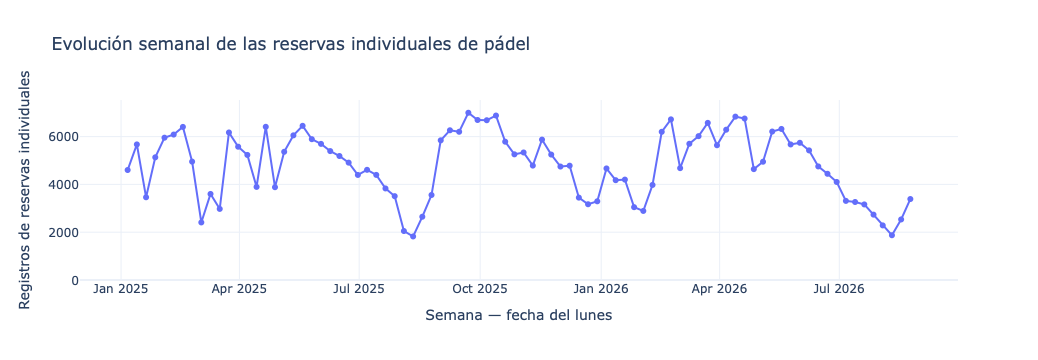

In [10]:
import plotly.express as px

# 1. Asignar cada registro a una semana de lunes a domingo.
# "semana" contiene la fecha del lunes.
reservas["semana"] = (
    reservas["fecha"]
    .dt.to_period("W-SUN")
    .dt.start_time
)

# 2. Contar registros y centros representados en cada semana
resumen_semanal = (
    reservas
    .groupby("semana")
    .agg(
        reservas_registradas=("fecha", "size"),
        centros_con_registros=("Centro deportivo", "nunique"),
        dias_con_registros=("fecha", "nunique")
    )
    .sort_index()
)

# 3. Incluir todas las semanas del intervalo.
# Las semanas sin registros se dejan vacías, no se rellenan con cero.
todas_las_semanas = pd.date_range(
    start=reservas["semana"].min(),
    end=reservas["semana"].max(),
    freq="W-MON"
)

resumen_semanal = (
    resumen_semanal
    .reindex(todas_las_semanas)
    .rename_axis("semana")
    .reset_index()
)

resumen_semanal["fin_semana"] = (
    resumen_semanal["semana"] + pd.Timedelta(days=6)
)

# 4. Marcar las semanas que quedan dentro del intervalo observado.
# Evitamos que los extremos parciales parezcan caídas de reservas.
resumen_semanal["dentro_intervalo_observado"] = (
    (resumen_semanal["semana"] >= reservas["fecha"].min())
    & (resumen_semanal["fin_semana"] <= reservas["fecha"].max())
)

semanas_grafico = resumen_semanal.loc[
    resumen_semanal["dentro_intervalo_observado"]
].copy()

# 5. Crear el gráfico interactivo
fig = px.line(
    semanas_grafico,
    x="semana",
    y="reservas_registradas",
    markers=True,
    title="Evolución semanal de las reservas individuales de pádel",
    labels={
        "semana": "Semana — fecha del lunes",
        "reservas_registradas": "Registros de reservas individuales",
        "centros_con_registros": "Centros con registros",
        "dias_con_registros": "Días con registros"
    },
    hover_data=["centros_con_registros", "dias_con_registros"],
    template="plotly_white"
)

fig.update_traces(connectgaps=False)
fig.update_layout(hovermode="x unified")
fig.update_yaxes(rangemode="tozero")
fig.show()

# 6. Guardar la tabla completa y el gráfico
resumen_semanal.to_csv(
    carpeta_analisis / "reservas_semanales.csv",
    index=False,
    encoding="utf-8-sig"
)

fig.write_html(
    str(carpeta_analisis / "evolucion_semanal.html"),
    include_plotlyjs=True
)

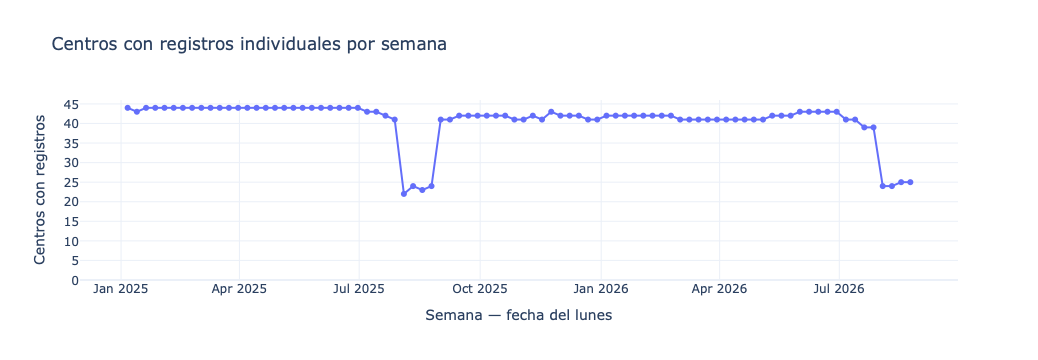

In [11]:
# Complemento del gráfico de reservas:
# número de centros con registros individuales cada semana.

fig_centros = px.line(
    semanas_grafico,
    x="semana",
    y="centros_con_registros",
    markers=True,
    title="Centros con registros individuales por semana",
    labels={
        "semana": "Semana — fecha del lunes",
        "centros_con_registros": "Centros con registros"
    },
    template="plotly_white"
)

fig_centros.update_traces(connectgaps=False)

fig_centros.update_yaxes(
    range=[0, reservas["Centro deportivo"].nunique() + 1],
    dtick=5
)

fig_centros.update_layout(hovermode="x unified")
fig_centros.show()

fig_centros.write_html(
    str(carpeta_analisis / "centros_con_registros_semanales.html"),
    include_plotlyjs=True
)

Número de fechas utilizadas para cada día de la semana:


,fechas_observadas
Lunes,87
Martes,86
Miércoles,84
Jueves,84
Viernes,87
Sábado,87
Domingo,87


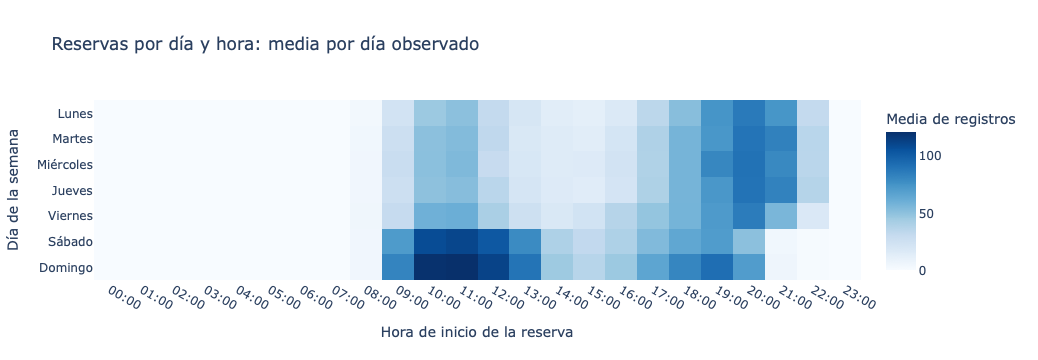

In [12]:
# 1. Preparar fecha y hora de inicio
datos_horarios = reservas.copy()

datos_horarios["fecha_dia"] = (
    datos_horarios["fecha"].dt.normalize()
)

# Agrupar los inicios en intervalos de una hora.
# Ejemplo: 18:00 y 18:30 se incluyen en la franja de las 18.
datos_horarios["hora"] = (
    pd.to_numeric(datos_horarios["hora_inicio_num"], errors="raise")
    // 1
).astype(int)

# 2. Contar los registros por fecha y hora
registros_por_dia_hora = (
    datos_horarios
    .groupby(["fecha_dia", "hora"])
    .size()
    .unstack("hora", fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

# Solo aparecen fechas con algún registro individual.
# Dentro de esas fechas, cero significa que no hay registros
# que comiencen en esa franja horaria.

# 3. Calcular la media para cada día de la semana
mapa_horario = (
    registros_por_dia_hora
    .groupby(registros_por_dia_hora.index.day_of_week)
    .mean()
    .reindex(range(7))
)

dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

mapa_horario.index = dias
mapa_horario.columns = [f"{hora:02d}:00" for hora in range(24)]

# 4. Mostrar cuántas fechas se utilizan para cada media
dias_observados = (
    datos_horarios[["fecha_dia"]]
    .drop_duplicates()
    .assign(dia_semana=lambda x: x["fecha_dia"].dt.day_of_week)
    .groupby("dia_semana")
    .size()
    .reindex(range(7), fill_value=0)
)

dias_observados.index = dias

print("Número de fechas utilizadas para cada día de la semana:")
display(dias_observados.rename("fechas_observadas").to_frame())

# 5. Dibujar el mapa de calor
fig_horario = px.imshow(
    mapa_horario,
    aspect="auto",
    color_continuous_scale="Blues",
    labels={
        "x": "Hora de inicio de la reserva",
        "y": "Día de la semana",
        "color": "Media de registros"
    },
    title="Reservas por día y hora: media por día observado",
    template="plotly_white"
)

fig_horario.update_traces(
    hovertemplate=(
        "%{y}, franja de las %{x}"
        "<br>Media de registros: %{z:.1f}"
        "<extra></extra>"
    )
)

fig_horario.show()

# 6. Guardar resultados
mapa_horario.to_csv(
    carpeta_analisis / "media_reservas_dia_hora.csv",
    index_label="dia_semana",
    encoding="utf-8-sig"
)

fig_horario.write_html(
    str(carpeta_analisis / "mapa_calor_dia_hora.html"),
    include_plotlyjs=True
)

In [13]:
# Variación respecto a la semana anterior
comparacion_semanal = (
    semanas_grafico
    .sort_values("semana")
    .copy()
)

# Recuperar los valores de la semana anterior
comparacion_semanal["reservas_semana_anterior"] = (
    comparacion_semanal["reservas_registradas"].shift(1)
)

comparacion_semanal["centros_semana_anterior"] = (
    comparacion_semanal["centros_con_registros"].shift(1)
)

# Evitar dividir entre cero.
# Si falta el dato anterior, la variación queda vacía.
base_comparacion = comparacion_semanal[
    "reservas_semana_anterior"
].where(
    comparacion_semanal["reservas_semana_anterior"] > 0
)

comparacion_semanal["variacion_pct"] = (
    (
        comparacion_semanal["reservas_registradas"]
        / base_comparacion
    ) - 1
) * 100

comparacion_semanal["cambio_numero_centros"] = (
    comparacion_semanal["centros_con_registros"]
    - comparacion_semanal["centros_semana_anterior"]
)

columnas_mostrar = [
    "semana",
    "reservas_registradas",
    "reservas_semana_anterior",
    "variacion_pct",
    "centros_con_registros",
    "cambio_numero_centros"
]

display(
    comparacion_semanal[columnas_mostrar]
    .tail(12)
    .round({"variacion_pct": 2})
)

comparacion_semanal.to_csv(
    carpeta_analisis / "comparacion_semanal.csv",
    index=False,
    encoding="utf-8-sig"
)

,semana,reservas_registradas,reservas_semana_anterior,variacion_pct,centros_con_registros,cambio_numero_centros
75,2026-06-08,5423,5741.0,-5.54,43,0.0
76,2026-06-15,4752,5423.0,-12.37,43,0.0
77,2026-06-22,4444,4752.0,-6.48,43,0.0
78,2026-06-29,4102,4444.0,-7.70,43,0.0
79,2026-07-06,3310,4102.0,-19.31,41,-2.0
80,2026-07-13,3264,3310.0,-1.39,41,0.0
81,2026-07-20,3162,3264.0,-3.12,39,-2.0
82,2026-07-27,2735,3162.0,-13.50,39,0.0
83,2026-08-03,2284,2735.0,-16.49,24,-15.0
84,2026-08-10,1873,2284.0,-17.99,24,0.0


In [14]:
# Preparar los datos que utilizará la aplicación Dash.
# "reservas" ya debe tener los nombres de centros normalizados.

carpeta_app = Path("Datos/app")
carpeta_app.mkdir(parents=True, exist_ok=True)

# Conservar únicamente las columnas necesarias para la aplicación.
datos_app = reservas[
    [
        "fecha",
        "Centro deportivo",
        "hora_inicio_num",
        "duracion_minutos"
    ]
].copy()

datos_app = datos_app.sort_values(
    ["fecha", "Centro deportivo", "hora_inicio_num"]
)

archivo_app = carpeta_app / "reservas_padel_app.csv"

datos_app.to_csv(
    archivo_app,
    index=False,
    encoding="utf-8-sig"
)

print("Registros exportados:", len(datos_app))
print("Centros:", datos_app["Centro deportivo"].nunique())
print("Primera fecha:", datos_app["fecha"].min())
print("Última fecha:", datos_app["fecha"].max())
print("Tamaño del archivo (MB):", round(
    archivo_app.stat().st_size / (1024 ** 2), 2
))
print("Archivo guardado en:", archivo_app.resolve())

Registros exportados: 417661
Centros: 45
Primera fecha: 2025-01-02 00:00:00
Última fecha: 2026-08-31 00:00:00
Tamaño del archivo (MB): 14.12
Archivo guardado en: /home/202207424/TFG analytics/Datos/app/reservas_padel_app.csv


## Conclusiones del análisis exploratorio

### 1. Datos analizados y normalización de centros

El conjunto analizado contiene 417.661 registros de reservas individuales,
con fechas comprendidas entre el 2 de enero de 2025 y el 31 de agosto de 2026:
256.122 corresponden a 2025 y 161.539 a 2026.

La normalización de los nombres ha reducido de 48 a 45 las denominaciones
distintas de centros deportivos, sin eliminar registros. Se corrigieron
espacios sobrantes y se unificaron «CDM El Quijote» y «El Quijote», al
observar unidades deportivas coincidentes y periodos mensuales
complementarios. Se conservaron los nombres originales para mantener
la trazabilidad de los cambios.

Los totales anuales no son directamente comparables, ya que 2025 incluye
doce meses y 2026 únicamente ocho.

### 2. Evolución semanal y cobertura

La serie semanal muestra una disminución de registros durante el verano
en ambos años, especialmente en agosto. En 2025 se observa una
recuperación posterior.

Este descenso coincide con una reducción del número de centros con
registros individuales: frente a aproximadamente 41–44 centros durante
buena parte del periodo, algunas semanas de agosto presentan alrededor
de 22–25.

Por tanto, la caída del total no puede atribuirse exclusivamente a una
menor demanda. También cambia el conjunto de centros representados.
Los datos disponibles no permiten distinguir por sí solos entre cierres,
ausencia de reservas y falta de información.

### 3. Distribución por día de la semana y hora

El mapa de calor muestra una mayor concentración de inicios de reservas
por la tarde entre semana. Durante los fines de semana destacan también
las franjas de la mañana.

El indicador representa la media de registros por franja horaria y día
observado para el conjunto de centros. Solo se incluyen fechas con
algún registro individual y se combinan ambos años.

Cada registro se asigna a su hora de inicio. Por ello, el mapa describe
cuándo comienzan las reservas, no cuántas pistas permanecen ocupadas
durante cada hora.

### 4. Variación respecto a la semana anterior

La variación porcentual permite identificar aumentos y disminuciones
del volumen registrado entre semanas consecutivas.

Por ejemplo, en la semana del 3 de agosto de 2026 los registros disminuyen
un 16,49 % respecto a la anterior, mientras que los centros con registros
pasan de 39 a 24. En la semana del 24 de agosto aumentan un 33,70 %,
manteniéndose en 25 el número de centros con registros.

Estos ejemplos muestran la necesidad de interpretar conjuntamente
el volumen y la cobertura. Un mismo número de centros no garantiza
que sean los mismos ni que aporten información igualmente completa.

### 5. Limitaciones y aplicación al proyecto

La ausencia de registros no se interpreta automáticamente como ausencia
de demanda ni como cierre de una instalación. Asimismo, encontrar
registros en un mes no garantiza que su información esté completa.

Sin datos sobre pistas disponibles, horarios de apertura y cierres,
no puede calcularse un porcentaje real de ocupación. Tampoco se observa
la demanda no satisfecha, como intentos de reserva sin disponibilidad.

Los tres indicadores desarrollados —volumen semanal, patrón por día
y hora y variación semanal— constituyen la base de la aplicación Dash.
Su interpretación deberá acompañarse del periodo seleccionado y de
información sobre la cobertura de los datos.